In [1]:
import os, sys
PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)

import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
from src.data import load_split, CLASSES

train_df, val_df, test_df = load_split(PROJECT_ROOT)

classes_idx = np.arange(len(CLASSES))
weights = compute_class_weight("balanced", classes=classes_idx, y=train_df["label"].values)
class_weight = {int(i): float(w) for i, w in zip(classes_idx, weights)}

summary = pd.DataFrame({
    "class": CLASSES,
    "train_images": [int((train_df["label"] == i).sum()) for i in classes_idx],
    "weight": [round(class_weight[i], 3) for i in classes_idx],
})
print(summary.to_string(index=False))
print("\nWeight ratio (max/min):", round(max(class_weight.values()) / min(class_weight.values()), 1))

class  train_images  weight
akiec           230   4.349
  bcc           366   2.733
  bkl           774   1.292
   df            76  13.162
  mel           778   1.286
   nv          4679   0.214
 vasc            99  10.104

Weight ratio (max/min): 61.6


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from src.data import make_dataset

IMG_SHAPE = (224, 224, 3)

# 1) Pretrained base, ImageNet weights, no original classification head
base = keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
base.trainable = False   # frozen: only our new head will learn at first

# 2) Our model: raw 0-255 pixels in -> MobileNetV2's expected [-1, 1] scaling -> base -> head
inputs = keras.Input(shape=IMG_SHAPE)
x = layers.Rescaling(1 / 127.5, offset=-1)(inputs)   # 0..255  ->  -1..1
x = base(x, training=False)                          # keeps BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
model = keras.Model(inputs, outputs, name="mobilenetv2_baseline")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# --- Sanity checks ---
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
frozen = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
print("Trainable params:", trainable)
print("Frozen params:", frozen)

val_ds = make_dataset(val_df, batch_size=32, training=False)
imgs, labels = next(iter(val_ds))
probs = model.predict(imgs, verbose=0)
print("Output shape:", probs.shape)
print("Row sums (should be ~1):", probs.sum(axis=1)[:3])
print("Untrained loss on this batch:", float(keras.losses.sparse_categorical_crossentropy(labels, probs).numpy().mean()))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step
Trainable params: 8967
Frozen params: 2257984
Output shape: (32, 7)
Row sums (should be ~1): [1. 1. 1.]
Untrained loss on this batch: 2.0192017555236816


In [3]:
import time
from sklearn.metrics import balanced_accuracy_score, f1_score

MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

train_ds = make_dataset(train_df, batch_size=32, training=True)
val_ds = make_dataset(val_df, batch_size=32, training=False)

# Early stopping and checkpointing on validation loss (not accuracy, which is misleading under imbalance)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, "mobilenetv2_head.keras"),
                                    monitor="val_loss", save_best_only=True),
]

t0 = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight,
    callbacks=callbacks,
)
print(f"\nTraining time: {(time.time() - t0) / 60:.1f} min")

# Validation metrics that matter under imbalance
val_probs = model.predict(val_ds, verbose=0)
val_pred = val_probs.argmax(axis=1)
y_val = val_df["label"].values
print("Val accuracy         :", round((val_pred == y_val).mean(), 4))
print("Val balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))
print("Val macro F1         :", round(f1_score(y_val, val_pred, average="macro"), 4))

Epoch 1/15


<project>\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


219/219 ━━━━━━━━━━━━━━━━━━━━ 202s 899ms/step - accuracy: 0.3843 - loss: 1.8027 - val_accuracy: 0.5398 - val_loss: 1.2858 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 185s 840ms/step - accuracy: 0.5276 - loss: 1.2758 - val_accuracy: 0.4576 - val_loss: 1.4936 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 177s 807ms/step - accuracy: 0.5661 - loss: 1.1556 - val_accuracy: 0.6168 - val_loss: 1.0423 - learning_rate: 0.0010
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 170s 775ms/step - accuracy: 0.5907 - loss: 1.0603 - val_accuracy: 0.6514 - val_loss: 0.9468 - learning_rate: 0.0010
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 169s 771ms/step - accuracy: 0.5963 - loss: 1.0176 - val_accuracy: 0.6482 - val_loss: 1.0009 - learning_rate: 0.0010
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 638ms/step - accuracy: 0.6255 - loss: 0.9654
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
219/219 ━━━━━━━━━━━━━━━━━━━━ 171s 778ms/step - accuracy: 0.6255 - l

              precision    recall  f1-score   support

       akiec      0.262     0.647     0.373        51
         bcc      0.451     0.481     0.465        77
         bkl      0.489     0.408     0.444       157
          df      0.134     0.474     0.209        19
         mel      0.335     0.541     0.413       170
          nv      0.927     0.716     0.808      1034
        vasc      0.415     0.917     0.571        24

    accuracy                          0.651      1532
   macro avg      0.430     0.597     0.469      1532
weighted avg      0.753     0.651     0.684      1532



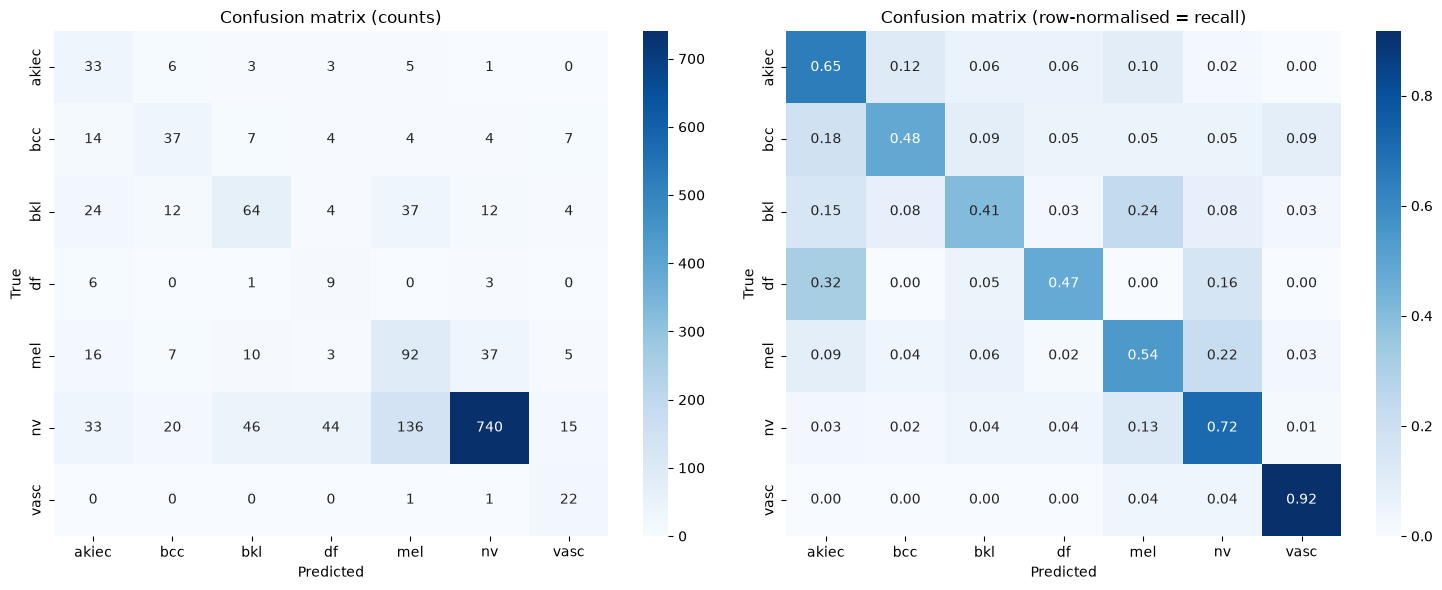

ROC-AUC akiec : 0.930
ROC-AUC bcc   : 0.943
ROC-AUC bkl   : 0.848
ROC-AUC df    : 0.865
ROC-AUC mel   : 0.820
ROC-AUC nv    : 0.896
ROC-AUC vasc  : 0.993


In [4]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

print(classification_report(y_val, val_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_val, val_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)   # rows = true class, so the diagonal is per-class recall

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalised = recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

# One-vs-rest ROC-AUC per class
for i, c in enumerate(CLASSES):
    auc = roc_auc_score((y_val == i).astype(int), val_probs[:, i])
    print(f"ROC-AUC {c:6s}: {auc:.3f}")

In [5]:
import json
from sklearn.metrics import recall_score, precision_score

results = {
    "model": "mobilenetv2_frozen_head_fullweights",
    "val_accuracy": float((val_pred == y_val).mean()),
    "val_balanced_accuracy": float(balanced_accuracy_score(y_val, val_pred)),
    "val_macro_f1": float(f1_score(y_val, val_pred, average="macro")),
    "mel_recall": float(recall_score(y_val, val_pred, labels=[4], average=None)[0]),
    "mel_precision": float(precision_score(y_val, val_pred, labels=[4], average=None)[0]),
    "best_epoch": 7,
}
os.makedirs(os.path.join(PROJECT_ROOT, "results"), exist_ok=True)
with open(os.path.join(PROJECT_ROOT, "results", "baseline_mobilenet_head.json"), "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

{
  "model": "mobilenetv2_frozen_head_fullweights",
  "val_accuracy": 0.6507832898172323,
  "val_balanced_accuracy": 0.5974880393348591,
  "val_macro_f1": 0.46925841578488725,
  "mel_recall": 0.5411764705882353,
  "mel_precision": 0.33454545454545453,
  "best_epoch": 7
}


In [6]:
import time
import json
from sklearn.metrics import (balanced_accuracy_score, f1_score,
                             recall_score, precision_score)

# 1) Softer weights: square root of the balanced weights
class_weight_sqrt = {i: float(np.sqrt(w)) for i, w in class_weight.items()}
print("sqrt weights:", {CLASSES[i]: round(w, 2) for i, w in class_weight_sqrt.items()})

# 2) Fresh model, identical architecture to Step 14
keras.backend.clear_session()
base2 = keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
base2.trainable = False
inp = keras.Input(shape=IMG_SHAPE)
h = layers.Rescaling(1 / 127.5, offset=-1)(inp)
h = base2(h, training=False)
h = layers.GlobalAveragePooling2D()(h)
h = layers.Dropout(0.3)(h)
out = layers.Dense(len(CLASSES), activation="softmax")(h)
model_sqrt = keras.Model(inp, out, name="mobilenetv2_sqrtweights")
model_sqrt.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])

train_ds = make_dataset(train_df, batch_size=32, training=True)
val_ds = make_dataset(val_df, batch_size=32, training=False)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, "mobilenetv2_head_sqrt.keras"),
                                    monitor="val_loss", save_best_only=True),
]

t0 = time.time()
hist2 = model_sqrt.fit(train_ds, validation_data=val_ds, epochs=15,
                       class_weight=class_weight_sqrt, callbacks=callbacks)
print(f"\nTraining time: {(time.time() - t0) / 60:.1f} min")
best_epoch2 = int(np.argmin(hist2.history["val_loss"])) + 1
print("Best epoch (lowest val_loss):", best_epoch2)

# 3) Same validation metrics as the baseline
val_probs2 = model_sqrt.predict(val_ds, verbose=0)
val_pred2 = val_probs2.argmax(axis=1)
print("Val accuracy         :", round((val_pred2 == y_val).mean(), 4))
print("Val balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred2), 4))
print("Val macro F1         :", round(f1_score(y_val, val_pred2, average="macro"), 4))
print("mel recall / precision:",
      round(recall_score(y_val, val_pred2, labels=[4], average=None)[0], 4), "/",
      round(precision_score(y_val, val_pred2, labels=[4], average=None)[0], 4))

res2 = {
    "model": "mobilenetv2_frozen_head_sqrtweights",
    "val_accuracy": float((val_pred2 == y_val).mean()),
    "val_balanced_accuracy": float(balanced_accuracy_score(y_val, val_pred2)),
    "val_macro_f1": float(f1_score(y_val, val_pred2, average="macro")),
    "mel_recall": float(recall_score(y_val, val_pred2, labels=[4], average=None)[0]),
    "mel_precision": float(precision_score(y_val, val_pred2, labels=[4], average=None)[0]),
    "best_epoch": best_epoch2,
}
with open(os.path.join(PROJECT_ROOT, "results", "baseline_mobilenet_head_sqrt.json"), "w") as f:
    json.dump(res2, f, indent=2)

sqrt weights: {'akiec': 2.09, 'bcc': 1.65, 'bkl': 1.14, 'df': 3.63, 'mel': 1.13, 'nv': 0.46, 'vasc': 3.18}

Epoch 1/15


<project>\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


219/219 ━━━━━━━━━━━━━━━━━━━━ 181s 804ms/step - accuracy: 0.6021 - loss: 1.2084 - val_accuracy: 0.6691 - val_loss: 0.9567 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 242s 1s/step - accuracy: 0.6797 - loss: 0.9198 - val_accuracy: 0.6717 - val_loss: 0.9066 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 193s 880ms/step - accuracy: 0.6994 - loss: 0.8364 - val_accuracy: 0.7454 - val_loss: 0.7444 - learning_rate: 0.0010
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 190s 863ms/step - accuracy: 0.7162 - loss: 0.7899 - val_accuracy: 0.7539 - val_loss: 0.7146 - learning_rate: 0.0010
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 198s 900ms/step - accuracy: 0.7265 - loss: 0.7673 - val_accuracy: 0.7030 - val_loss: 0.7832 - learning_rate: 0.0010
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 723ms/step - accuracy: 0.7339 - loss: 0.7330
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
219/219 ━━━━━━━━━━━━━━━━━━━━ 193s 880ms/step - accuracy: 0.7339 - loss

In [7]:
print(json.load(open(os.path.join(PROJECT_ROOT, "results", "baseline_mobilenet_head_sqrt.json"))))

{'model': 'mobilenetv2_frozen_head_sqrtweights', 'val_accuracy': 0.7591383812010444, 'val_balanced_accuracy': 0.5358785513387049, 'val_macro_f1': 0.5351182085610059, 'mel_recall': 0.48823529411764705, 'mel_precision': 0.453551912568306, 'best_epoch': 7}
